# Practicum 1. Анализ продаж в pandas

Учебный ноутбук по датасету транзакций продаж `transactions.csv`
(1 008 688 строк, период 01.09.2017 – 31.10.2019).

**Колонки:** `tr_date` (дата продажи), `tcode` (чек), `client` (клиент),
`item` (товар), `item_group` (товарная группа), `quantity` (количество),
`amount` (сумма).

**Структура:** каждый шаг — это отдельный markdown-блок с формулировкой
промпта к AI-ассистенту (Gigacode, Continue, ChatGPT и т.п.) и код на pandas,
который этот промпт реализует. Ячейки выполняются последовательно сверху вниз.

**Перед запуском:** положите `transactions.csv` рядом с ноутбуком и установите
зависимости `pip install pandas matplotlib seaborn`.


Импорты и настройки окружения:

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", context="notebook")

DATA_PATH = Path("transactions.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Нет файла {DATA_PATH.resolve()} — положите его рядом с ноутбуком")


def fmt_num(value, nd=2):
    # 1 234,56: пробел между разрядами, запятая в дробной части
    return f"{value:,.{nd}f}".replace(",", " ").replace(".", ",")


def fmt_int(value):
    return fmt_num(value, 0)


## Шаг 1. Загрузка CSV в DataFrame

**Промпт к AI-ассистенту:**

> напиши код на питоне для загрузки csv файла "transactions.csv" в DataFrame
> при помощи pandas. Датасет содержит транзакции продаж с колонками:
> tr_date, tcode, client, item, item_group, quantity, amount. Убедись что
> колонка Date преобразована в тип datetime. Выведи первые 5 строк и
> основную информацию о датасете

В датасете колонка с датой называется `tr_date` — её и приводим к `datetime`
(параметр `errors="coerce"` превращает нераспознанные значения в `NaT`,
а не роняет скрипт).

In [2]:
df = pd.read_csv(DATA_PATH)

# колонка с датой в датасете называется tr_date
df["tr_date"] = pd.to_datetime(df["tr_date"], errors="coerce")

print("Первые 5 строк:")
print(df.head(5).to_string())

print("\nИнформация о датасете:")
df.info()


Первые 5 строк:
     tr_date          tcode       client      item                    item_group  quantity  amount
0 2017-09-01  code000000001  client13166   sku8444              Скобяные изделия         1      29
1 2017-09-01  code000000001  client13166  sku12545  Оборудование для сада и дачи         1     329
2 2017-09-01  code000000001  client13166   sku3391                   Инструменты         1     169
3 2017-09-01  code000000001  client13166  sku20444                   Инструменты         2     578
4 2017-09-01  code000000002   client1239  sku29959              Скобяные изделия         1     329

Информация о датасете:
<class 'pandas.DataFrame'>
RangeIndex: 1008688 entries, 0 to 1008687
Data columns (total 7 columns):
 #   Column      Non-Null Count    Dtype         
---  ------      --------------    -----         
 0   tr_date     1008688 non-null  datetime64[us]
 1   tcode       1008688 non-null  str           
 2   client      1008688 non-null  str           
 3   item      

## Шаг 2. Статистический анализ датасета

**Промпт к AI-ассистенту:**

> Проведи статистический анализ DataFrame с продажами: 1. Выведи общую
> информацию: количество строк, столбцов, типы данных 2. Рассчитай
> описательную статистику для всех числовых колонок (quantity, amount):
> min, max, mean, std, median, 25%, 75% 3. Проверь наличие пропущенных
> значений 4. Для каждого числового столбца выведи уникальных значений и их
> диапазоны

`df.info()` уже даёт строки/типы/память, поэтому здесь добавляем то, чего в
нём нет: явную описательную статистику и диапазоны уникальных значений.

In [3]:
print(f"Строк: {fmt_int(len(df))} | столбцов: {df.shape[1]}")
print("\nТипы данных:")
print(df.dtypes.to_string())

numeric_cols = ["quantity", "amount"]
stats = pd.DataFrame(
    {
        col: {
            "count": df[col].count(),
            "min": df[col].min(),
            "25%": df[col].quantile(0.25),
            "median (50%)": df[col].median(),
            "75%": df[col].quantile(0.75),
            "max": df[col].max(),
            "mean": df[col].mean(),
            "std": df[col].std(),
        }
        for col in numeric_cols
    }
)
print("\nОписательная статистика числовых колонок:")
print(stats.to_string(float_format=fmt_num))

print("\nПропущенные значения по колонкам:")
print(df.isna().sum().to_string())

print("\nУникальные значения и диапазоны:")
for col in numeric_cols:
    s = df[col]
    print(
        f"  {col}: уникальных {s.nunique()}, "
        f"диапазон {fmt_num(s.min(), 0)} – {fmt_num(s.max(), 0)}, "
        f"нулей {int((s == 0).sum())}"
    )


Строк: 1 008 688 | столбцов: 7

Типы данных:
tr_date       datetime64[us]
tcode                    str
client                   str
item                     str
item_group               str
quantity               int64
amount                 int64

Описательная статистика числовых колонок:
                 quantity       amount
count        1 008 688,00 1 008 688,00
min                  0,00         0,00
25%                  1,00        56,00
median (50%)         1,00       150,00
75%                  2,00       425,00
max              1 100,00   213 177,00
mean                 2,22       623,19
std                  5,03     1 878,42

Пропущенные значения по колонкам:
tr_date       0
tcode         0
client        0
item          0
item_group    0
quantity      0
amount        0

Уникальные значения и диапазоны:
  quantity: уникальных 198, диапазон 0 – 1 100, нулей 1
  amount: уникальных 11181, диапазон 0 – 213 177, нулей 17


## Шаг 3. Распределения quantity и amount

**Промпт к AI-ассистенту:**

> Создай графики для анализа распределения quantity и amount из DataFrame df.
> Используй sns.histplot с kde=True и sns.boxplot. Сделай два окна: одно с
> гистограммами, второе с box plot.

Два нюанса на миллионе строк: KDE на всех значениях съедает гигабайты
памяти (сетка KDE × данные), поэтому для графика берём подвыборку
100 000 строк; и ось X обрезаем по 99,5-му процентилю, иначе основной
массив данных сжимается в один столбик у нуля.

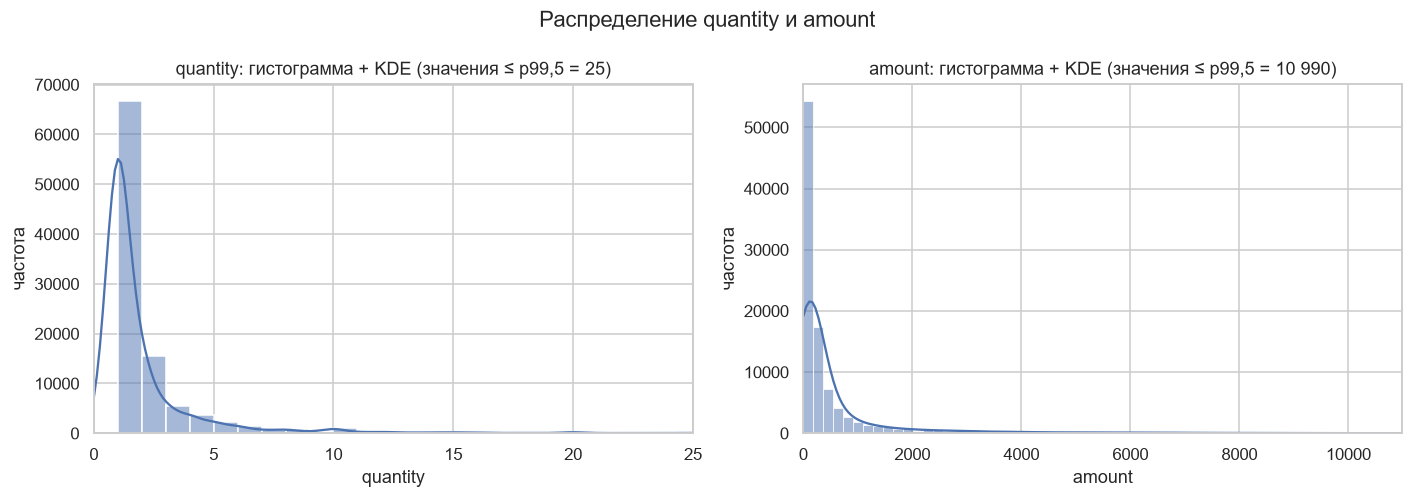

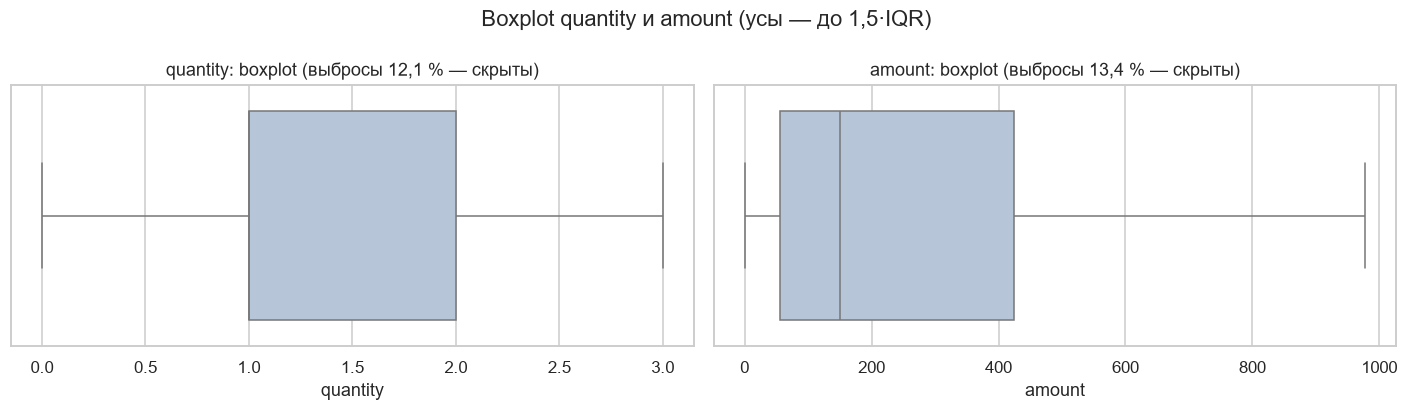

In [4]:
SAMPLE_SIZE = 100_000
COLUMNS = ["quantity", "amount"]


def plot_data(series, upper):
    # подвыборка для KDE + отбрасываем 0,5 % самых больших значений
    data = series.dropna()
    if len(data) > SAMPLE_SIZE:
        data = data.sample(SAMPLE_SIZE, random_state=42)
    return data[data <= upper]


def choose_bins(data, upper):
    # для целых величин с малым диапазоном шаг бина 1, иначе 60 бинов
    if upper <= 100 and bool((data % 1 == 0).all()):
        return np.arange(0, upper + 1)
    return np.linspace(0, upper, 61)


# окно 1 — гистограммы с KDE
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, col in zip(axes, COLUMNS):
    upper = df[col].quantile(0.995)
    data = plot_data(df[col], upper)
    sns.histplot(
        x=data,
        kde=True,
        bins=choose_bins(data, upper),
        kde_kws={"bw_adjust": 2.0},
        ax=ax,
    )
    ax.set_xlim(0, upper)
    ax.set_title(f"{col}: гистограмма + KDE (значения ≤ p99,5 = {fmt_num(upper, 0)})")
    ax.set_xlabel(col)
    ax.set_ylabel("частота")
fig.suptitle("Распределение quantity и amount")
fig.tight_layout()
plt.show()

# окно 2 — boxplot
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, col in zip(axes, COLUMNS):
    q1, q3 = df[col].quantile([0.25, 0.75])
    outlier_share = (df[col] > q3 + 1.5 * (q3 - q1)).mean()
    sns.boxplot(x=df[col], ax=ax, showfliers=False, color="lightsteelblue")
    ax.set_title(f"{col}: boxplot (выбросы {fmt_num(outlier_share * 100, 1)} % — скрыты)")
    ax.set_xlabel(col)
fig.suptitle("Boxplot quantity и amount (усы — до 1,5·IQR)")
fig.tight_layout()
plt.show()


## Шаг 4. ТОП-5 товаров по сумме продаж

**Промпт к AI-ассистенту:**

> На основе DataFrame с продажами: 1. Сгруппируй данные по колонке item
> (товар) 2. Для каждого товара рассчитай сумму двух метрик: - Кол-во:
> sum(quantity) - Сумма продаж: sum(amount) 3. Отсортируй результат по сумме
> продаж в убывающем порядке 4. Выведи только ТОП-5 товаров с самыми
> большими продажами 5. Сохрани результат в переменную 'top_5_products'

In [5]:
top_5_products = (
    df.groupby("item", as_index=False)
    .agg(
        quantity=("quantity", "sum"),
        amount=("amount", "sum"),
    )
    .sort_values("amount", ascending=False)
    .head(5)
    .reset_index(drop=True)
)

print("ТОП-5 товаров по сумме продаж:")
print(
    top_5_products.to_string(
        index=False,
        formatters={"quantity": lambda x: fmt_num(x, 0), "amount": lambda x: fmt_num(x, 0)},
    )
)
print(f"\nТОП-5 дают {fmt_num(top_5_products['amount'].sum() / df['amount'].sum() * 100, 2)} % выручки")


ТОП-5 товаров по сумме продаж:
    item quantity    amount
sku26161   18 902 5 373 638
sku18199    7 250 3 951 361
sku21947   15 304 3 918 570
sku28128    7 705 3 027 786
 sku8342    3 512 2 113 158

ТОП-5 дают 2,92 % выручки


## Шаг 5. Функция get_top_products(df, n=5)

**Промпт к AI-ассистенту:**

> Переделай предыдущий код так, чтобы число ТОП товаров было параметром
> (переменной N). Создай функцию get_top_products(df, n=5), которая:
> 1. Принимает DataFrame df и параметр n (количество товаров) 2. Выполняет
> группировку, сортировку и фильтрацию как в предыдущем примере 3. Возвращает
> DataFrame с n лучшими товарами Протестируй функцию с разными значениями N:
> - N = 5 - N = 10

In [6]:
def get_top_products(df: pd.DataFrame, n: int = 5) -> pd.DataFrame:
    if n <= 0:
        raise ValueError(f"n должно быть положительным, получено n={n}")
    return (
        df.groupby("item", as_index=False)
        .agg(quantity=("quantity", "sum"), amount=("amount", "sum"))
        .sort_values("amount", ascending=False)
        .head(n)
        .reset_index(drop=True)
    )


for n in (5, 10):
    print(f"\nТОП-{n} товаров:")
    print(
        get_top_products(df, n).to_string(
            index=False,
            formatters={"quantity": lambda x: fmt_num(x, 0), "amount": lambda x: fmt_num(x, 0)},
        )
    )

top_5_products = get_top_products(df, n=5)
print(f"\nПо умолчанию n=5, форма результата: {top_5_products.shape}")



ТОП-5 товаров:
    item quantity    amount
sku26161   18 902 5 373 638
sku18199    7 250 3 951 361
sku21947   15 304 3 918 570
sku28128    7 705 3 027 786
 sku8342    3 512 2 113 158

ТОП-10 товаров:
    item quantity    amount
sku26161   18 902 5 373 638
sku18199    7 250 3 951 361
sku21947   15 304 3 918 570
sku28128    7 705 3 027 786
 sku8342    3 512 2 113 158
sku29626   13 669 1 973 964
 sku9018    3 299 1 706 341
 sku9471    5 045 1 675 843
sku25074    6 125 1 668 585
sku27791    8 384 1 645 042

По умолчанию n=5, форма результата: (5, 3)


## Шаг 6. ТОП-5 за последние 6 месяцев

**Промпт к AI-ассистенту:**

> На основе исходного DataFrame: 1. Задай переменную end_date = '2019-10-31'
> 2. Задай переменную period_months = 6 3. Рассчитай начальную дату:
> start_date = end_date - 6 месяцев 4. Отфильтруй DataFrame так, чтобы
> осталась только дата >= start_date и дата <= end_date 5. На отфильтрованных
> данных запусти функцию get_top_products(filtered_df, n=5) 6. Выведи
> результат

`pd.DateOffset(months=6)` от 31.10.2019 даёт 30.04.2019 — pandas корректно
«прижимает» 31-е число к последнему дню апреля. Поэтому в выборку попадает и
30 апреля: 350 864 строки. В шаге 15 период задан явными датами
01.05–31.10.2019 — это на 3 127 строк меньше; расхождение намеренно
оговаривается, чтобы цифры в шагах 6 и 15 не выглядели ошибкой.

In [7]:
end_date = "2019-10-31"
period_months = 6

end_ts = pd.Timestamp(end_date)
start_date = end_ts - pd.DateOffset(months=period_months)

filtered_df = df[(df["tr_date"] >= start_date) & (df["tr_date"] <= end_ts)]
df_last_6m = filtered_df.copy()

print(f"Период: {start_date:%d.%m.%Y} – {end_ts:%d.%m.%Y} ({period_months} мес.)")
print(f"Строк после фильтра: {fmt_int(len(df_last_6m))} из {fmt_int(len(df))}")
print(
    "Фактический диапазон дат:",
    f"{df_last_6m['tr_date'].min():%d.%m.%Y} – {df_last_6m['tr_date'].max():%d.%m.%Y}",
)
print("\nТОП-5 товаров за период:")
print(
    get_top_products(df_last_6m, n=5).to_string(
        index=False,
        formatters={"quantity": lambda x: fmt_num(x, 0), "amount": lambda x: fmt_num(x, 0)},
    )
)


Период: 30.04.2019 – 31.10.2019 (6 мес.)
Строк после фильтра: 350 864 из 1 008 688
Фактический диапазон дат: 30.04.2019 – 31.10.2019

ТОП-5 товаров за период:
    item quantity    amount
sku26161    7 993 2 379 453
sku18199    3 066 1 848 072
sku21947    5 831 1 543 669
 sku8342    1 509   970 053
sku22208       89   896 275


## Шаг 7. Статистика по клиентам

**Промпт к AI-ассистенту:**

> На основе исходного DataFrame выполни анализ по клиентам: 1. Сгруппируй
> данные по client 2. Для каждого клиента рассчитай: - Общее количество
> товаров (sum(quantity)) - Общую сумму закупок (sum(amount)) - Количество
> уникальных дат визитов (nunique(tr_date)) 3. Отсортируй по сумме закупок в
> убывающем порядке 4. Сохрани результат в переменную 'client_stats' После
> этого выведи статистику по столбцам: - Для quantity: min, max, mean, median
> - Для amount: min, max, mean, median - Для количества дат визитов: min,
> max, mean

In [8]:
client_stats = (
    df.groupby("client", as_index=False)
    .agg(
        total_quantity=("quantity", "sum"),
        total_amount=("amount", "sum"),
        visit_dates=("tr_date", "nunique"),
    )
    .sort_values("total_amount", ascending=False)
    .reset_index(drop=True)
)

print(f"Клиентов: {fmt_int(len(client_stats))}")
print("\nТОП-5 клиентов по сумме закупок:")
print(
    client_stats.head(5).to_string(
        index=False,
        formatters={
            "total_quantity": lambda x: fmt_num(x, 0),
            "total_amount": lambda x: fmt_num(x, 0),
            "visit_dates": lambda x: fmt_num(x, 0),
        },
    )
)

print("\nСтатистика по столбцам:")
for col in ["total_quantity", "total_amount", "visit_dates"]:
    s = client_stats[col]
    print(
        f"  {col:<15} min={fmt_num(s.min(), 0):>11}  max={fmt_num(s.max(), 0):>10}  "
        f"mean={fmt_num(s.mean()):>10}  median={fmt_num(s.median())}"
    )


Клиентов: 42 746

ТОП-5 клиентов по сумме закупок:
     client total_quantity total_amount visit_dates
client29182          3 434    3 887 309         107
client15654          5 457    1 443 255         174
 client8778          1 617      986 618          17
 client1704          1 187      636 101          23
client33032          1 255      537 397          74

Статистика по столбцам:
  total_quantity  min=          1  max=     5 457  mean=     52,44  median=21,00
  total_amount    min=         10  max= 3 887 309  mean= 14 705,66  median=6 410,00
  visit_dates     min=          1  max=       174  mean=      6,18  median=3,00


## Шаг 8. Клиенты-экстремумы

**Промпт к AI-ассистенту:**

> На основе датафрейма client_stats: 1. Отфильтруй клиентов, у которых:
> - Количество товаров >= 2000 ИЛИ - Сумма >= 500000 2. Выведи количество
> найденных клиентов и их список 3. Покажи этих клиентов с их основными
> характеристиками 4. Опционально: сохрани их ID для дальнейшего анализа в
> переменную 'extreme_clients'

Условие именно **ИЛИ**: с одним только порогом по сумме теряются оптовики
с большим количеством штук, но дешёвым ассортиментом.

In [9]:
extreme = client_stats[
    (client_stats["total_quantity"] >= 2000) | (client_stats["total_amount"] >= 500_000)
].copy()

# производные характеристики: средний чек за визит и средняя цена единицы
extreme["avg_check"] = extreme["total_amount"] / extreme["visit_dates"]
extreme["avg_price"] = extreme["total_amount"] / extreme["total_quantity"]

extreme_clients = extreme["client"].tolist()

print(f"Найдено клиентов: {len(extreme)} из {fmt_int(len(client_stats))}")
print("\nСписок ID:")
print(extreme_clients)
print("\nХарактеристики:")
print(
    extreme.to_string(
        index=False,
        formatters={
            "total_quantity": lambda x: fmt_num(x, 0),
            "total_amount": lambda x: fmt_num(x, 0),
            "visit_dates": lambda x: fmt_num(x, 0),
            "avg_check": lambda x: fmt_num(x, 0),
            "avg_price": lambda x: fmt_num(x, 0),
        },
    )
)


Найдено клиентов: 9 из 42 746

Список ID:
['client29182', 'client15654', 'client8778', 'client1704', 'client33032', 'client37582', 'client30977', 'client34081', 'client20310']

Характеристики:
     client total_quantity total_amount visit_dates avg_check avg_price
client29182          3 434    3 887 309         107    36 330     1 132
client15654          5 457    1 443 255         174     8 295       264
 client8778          1 617      986 618          17    58 036       610
 client1704          1 187      636 101          23    27 657       536
client33032          1 255      537 397          74     7 262       428
client37582          2 526      502 515         159     3 160       199
client30977          2 234      407 138         121     3 365       182
client34081          2 470      386 355         157     2 461       156
client20310          3 265      366 035         102     3 589       112


## Шаг 9. Клиенты с одной датой визита

**Промпт к AI-ассистенту:**

> На основе датафрейма client_stats: 1. Отфильтруй клиентов, у которых
> количество дат визитов == 1 2. Подсчитай количество таких клиентов
> 3. Выведи статистику по этим клиентам: - Сколько их всего - Какой средний чек
> у них - Какой средний объем покупок

In [10]:
one_visit = client_stats[client_stats["visit_dates"] == 1]

print(f"Клиентов с одной датой визита: {fmt_int(len(one_visit))}")
print(f"Доля от всех клиентов: {fmt_num(len(one_visit) / len(client_stats) * 100)} %")
print(f"Средний чек: {fmt_num(one_visit['total_amount'].mean())} руб.")
print(f"Медианный чек: {fmt_num(one_visit['total_amount'].median())} руб.")
print(f"Средний объём покупок: {fmt_num(one_visit['total_quantity'].mean())} шт.")
print(f"Медианный объём покупок: {fmt_num(one_visit['total_quantity'].median())} шт.")
print(
    f"Диапазон чека: {fmt_num(one_visit['total_amount'].min(), 0)} – "
    f"{fmt_num(one_visit['total_amount'].max(), 0)} руб."
)


Клиентов с одной датой визита: 12 859
Доля от всех клиентов: 30,08 %
Средний чек: 3 535,45 руб.
Медианный чек: 1 892,00 руб.
Средний объём покупок: 8,67 шт.
Медианный объём покупок: 4,00 шт.
Диапазон чека: 10 – 125 860 руб.


## Шаг 10. Цена единицы товара: price = amount / quantity

**Промпт к AI-ассистенту:**

> На основе исходного DataFrame: 1. Перед расчетом убедись, что нет строк с
> quantity = 0 (это может привести к делению на 0) - Подсчитай количество
> таких строк - Если есть, выведи их и удали из DataFrame 2. Создай новый
> столбец 'price' = amount / quantity 3. Выведи статистику по новому столбцу
> price: - min, max, mean, median 4. Выведи первые 10 строк исходного
> DataFrame + новый столбец price

В датасете нашлась ровно одна такая строка (quantity = 0, amount = 1) — она
удаляется, иначе `1/0` дал бы `inf` и испортил `mean`/`std`.

In [11]:
zero_qty = df[df["quantity"] == 0]
print(f"Строк с quantity = 0: {len(zero_qty)}")
if not zero_qty.empty:
    print("\nЭти строки (удаляются):")
    print(zero_qty.to_string())
    df = df[df["quantity"] != 0].copy()
    print(f"\nСтрок после удаления: {fmt_int(len(df))}")

df["price"] = df["amount"] / df["quantity"]

print("\nСтатистика по price (руб. за единицу):")
print(f"  min:    {fmt_num(df['price'].min())}")
print(f"  max:    {fmt_num(df['price'].max())}")
print(f"  mean:   {fmt_num(df['price'].mean())}")
print(f"  median: {fmt_num(df['price'].median())}")

print("\nПервые 10 строк с новым столбцом price:")
print(df.head(10).to_string())


Строк с quantity = 0: 1

Эти строки (удаляются):
          tr_date          tcode       client      item        item_group  quantity  amount
920771 2019-09-14  code000261741  client24307  sku26360  Скобяные изделия         0       1

Строк после удаления: 1 008 687

Статистика по price (руб. за единицу):
  min:    0,00
  max:    119 500,00
  mean:   389,78
  median: 102,89

Первые 10 строк с новым столбцом price:
     tr_date          tcode       client      item                    item_group  quantity  amount  price
0 2017-09-01  code000000001  client13166   sku8444              Скобяные изделия         1      29   29.0
1 2017-09-01  code000000001  client13166  sku12545  Оборудование для сада и дачи         1     329  329.0
2 2017-09-01  code000000001  client13166   sku3391                   Инструменты         1     169  169.0
3 2017-09-01  code000000001  client13166  sku20444                   Инструменты         2     578  289.0
4 2017-09-01  code000000002   client1239  sku29959   

## Шаг 11. Выбросы по цене (метод IQR)

**Промпт к AI-ассистенту:**

> На основе DataFrame с рассчитанной ценой товара: 1. Выведи описательную
> статистику столбца 'price': - Квартили (25%, 50%, 75%) - Минимум и максимум
> - Межквартильный диапазон (IQR = Q3 - Q1) 2. Рассчитай границы для
> потенциальных выбросов: - lower_bound = Q1 - 1.5 * IQR - upper_bound = Q3 +
> 1.5 * IQR 3. Подсчитай количество выбросов (цены за пределами этих границ)
> 4. Выведи примеры выбросов (10 самых дорогих и 10 самых дешевых товаров)
> создай визуализацию гистограммы и box plot

Описательная статистика price:
  минимум          0,00
  Q1 (25 %)        39,00
  медиана (50 %)   102,89
  Q3 (75 %)        269,00
  максимум         119 500,00
  IQR = Q3 - Q1    230,00

Границы выбросов:
  lower_bound = Q1 - 1.5*IQR = -306,00
  upper_bound = Q3 + 1.5*IQR = 614,00

Выбросы:
  дешевле нижней границы: 0
  дороже верхней границы: 112 596
  всего: 112 596 (11,16 % строк), дают 57,70 % выручки

10 самых дорогих строк:
   tr_date         tcode      client     item                   item_group  quantity  amount    price
2019-06-03 code000202226   client319  sku8449 Оборудование для сада и дачи         1  119500 119500.0
2018-07-13 code000061932 client41335  sku6834               Садовая мебель         1   76990  76990.0
2018-04-10 code000036775 client41374 sku27261               Садовая мебель         1   74990  74990.0
2019-08-04 code000238163 client29707  sku6834               Садовая мебель         1   74990  74990.0
2019-05-23 code000195742 client29182  sku5775         

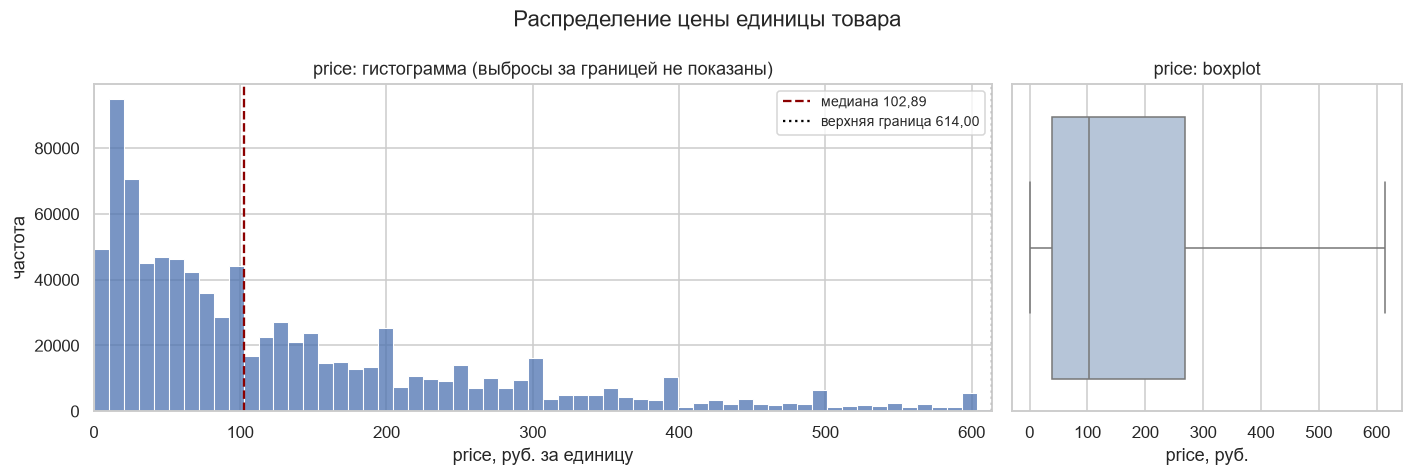

In [12]:
price = df["price"]
q1, q2, q3 = price.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print("Описательная статистика price:")
for title, value in [
    ("минимум", price.min()),
    ("Q1 (25 %)", q1),
    ("медиана (50 %)", q2),
    ("Q3 (75 %)", q3),
    ("максимум", price.max()),
    ("IQR = Q3 - Q1", iqr),
]:
    print(f"  {title:<16} {fmt_num(value)}")

print("\nГраницы выбросов:")
print(f"  lower_bound = Q1 - 1.5*IQR = {fmt_num(lower_bound)}")
print(f"  upper_bound = Q3 + 1.5*IQR = {fmt_num(upper_bound)}")

is_outlier = (price < lower_bound) | (price > upper_bound)
print("\nВыбросы:")
print(f"  дешевле нижней границы: {fmt_int(int((price < lower_bound).sum()))}")
print(f"  дороже верхней границы: {fmt_int(int((price > upper_bound).sum()))}")
print(
    f"  всего: {fmt_int(int(is_outlier.sum()))} "
    f"({fmt_num(is_outlier.mean() * 100)} % строк), "
    f"дают {fmt_num(df.loc[is_outlier, 'amount'].sum() / df['amount'].sum() * 100)} % выручки"
)

show_cols = ["tr_date", "tcode", "client", "item", "item_group", "quantity", "amount", "price"]
print("\n10 самых дорогих строк:")
print(df.nlargest(10, "price")[show_cols].to_string(index=False))
print("\n10 самых дешёвых строк:")
print(df.nsmallest(10, "price")[show_cols].to_string(index=False))

fig, (ax_hist, ax_box) = plt.subplots(
    1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [2.3, 1]}
)
sns.histplot(x=price[price <= upper_bound], bins=60, ax=ax_hist)
ax_hist.axvline(q2, color="darkred", linestyle="--", label=f"медиана {fmt_num(q2)}")
ax_hist.axvline(upper_bound, color="black", linestyle=":", label=f"верхняя граница {fmt_num(upper_bound)}")
ax_hist.set_xlim(0, upper_bound)
ax_hist.set_title("price: гистограмма (выбросы за границей не показаны)")
ax_hist.set_xlabel("price, руб. за единицу")
ax_hist.set_ylabel("частота")
ax_hist.legend(fontsize=9)

sns.boxplot(x=price, ax=ax_box, showfliers=False, color="lightsteelblue")
ax_box.set_title("price: boxplot")
ax_box.set_xlabel("price, руб.")
fig.suptitle("Распределение цены единицы товара")
fig.tight_layout()
plt.show()


## Шаг 12. ABC-анализ товаров по сумме продаж

**Промпт к AI-ассистенту:**

> Выполни ABC-анализ товаров по сумме продаж: 1. Сгруппируй данные по item и
> рассчитай сумму продаж каждого товара 2. Отсортируй товары по сумме продаж в
> убывающем порядке 3. Рассчитай накопительный процент (cumulative %) для
> каждого товара: - Общая сумма всех продаж = total_sum - Для каждого товара:
> cumulative_sum / total_sum * 100 4. На основе накопительного процента
> распредели товары на группы: - Группа A: cumulative % <= 80% - Группа B:
> cumulative % > 80% and <= 95% - Группа C: cumulative % > 95% 5. Выведи
> количество товаров в каждой группе и примеры товаров из каждой группы

In [13]:
abc = (
    df.groupby("item", as_index=False)
    .agg(
        total_quantity=("quantity", "sum"),
        total_amount=("amount", "sum"),
    )
    .sort_values("total_amount", ascending=False)
    .reset_index(drop=True)
)

total_sum = abc["total_amount"].sum()
abc["cumulative_sum"] = abc["total_amount"].cumsum()
abc["cumulative_pct"] = abc["cumulative_sum"] / total_sum * 100

abc["group"] = np.select(
    [abc["cumulative_pct"] <= 80, abc["cumulative_pct"] <= 95],
    ["A", "B"],
    default="C",
)

print("Количество товаров по группам:")
for group in ["A", "B", "C"]:
    part = abc[abc["group"] == group]
    print(
        f"  {group}: {fmt_int(len(part))} товаров "
        f"({fmt_num(len(part) / len(abc) * 100)} % ассортимента), "
        f"{fmt_num(part['total_amount'].sum() / total_sum * 100)} % выручки"
    )

for group, n in [("A", 5), ("B", 3), ("C", 3)]:
    print(f"\nПримеры группы {group} (первые {n}):")
    print(
        abc[abc["group"] == group]
        .head(n)[["item", "total_quantity", "total_amount", "cumulative_pct"]]
        .to_string(
            index=False,
            formatters={
                "total_quantity": lambda x: fmt_num(x, 0),
                "total_amount": lambda x: fmt_num(x, 0),
                "cumulative_pct": lambda x: fmt_num(x),
            },
        )
    )


Количество товаров по группам:
  A: 5 353 товаров (17,51 % ассортимента), 80,00 % выручки
  B: 8 234 товаров (26,94 % ассортимента), 15,00 % выручки
  C: 16 979 товаров (55,55 % ассортимента), 5,00 % выручки

Примеры группы A (первые 5):
    item total_quantity total_amount cumulative_pct
sku26161         18 902    5 373 638           0,85
sku18199          7 250    3 951 361           1,48
sku21947         15 304    3 918 570           2,11
sku28128          7 705    3 027 786           2,59
 sku8342          3 512    2 113 158           2,92

Примеры группы B (первые 3):
    item total_quantity total_amount cumulative_pct
sku10822             60       22 836          80,00
sku10724             18       22 834          80,01
sku29015             29       22 826          80,01

Примеры группы C (первые 3):
    item total_quantity total_amount cumulative_pct
sku18189             16        5 357          95,00
sku13438            158        5 357          95,00
  sku872             24   

## Шаг 13. XYZ-анализ товаров по количеству

**Промпт к AI-ассистенту:**

> Дополни XYZ-анализ товаров (по количеству): Используй для расчета
> коэффициент вариации = std / mean * 100 3. На основе коэффициента вариации
> распредели товары: - Группа X: CV < 15% - Группа Y: 15% <= CV <= 25% -
> Группа Z: CV > 25% 4. Выведи количество товаров в каждой группе

CV считаем по месяцам. Если заполнить месяцы без продаж нулями, то **все**
30 566 товаров попадут в Z (медианный CV 229 %), потому что товар продаётся
в среднем 6 месяцев из 26. Поэтому ряд берём по активным месяцам товара —
флаг `with_zeros` позволяет вернуться к «учебному» варианту.

In [14]:
monthly = (
    df.assign(month=df["tr_date"].dt.to_period("M"))
    .groupby(["item", "month"], as_index=False)["quantity"]
    .sum()
)
pivot = (
    monthly.pivot(index="item", columns="month", values="quantity")
    .fillna(0)
    .sort_index(axis=1)
)

active = pivot.replace(0, np.nan)          # только месяцы с продажами
cv = active.std(axis=1, ddof=1) / active.mean(axis=1) * 100

xyz = pd.DataFrame(
    {
        "item": pivot.index,
        "months": (pivot > 0).sum(axis=1).values,
        "periods": pivot.shape[1],
        "mean_month": active.mean(axis=1).values,
        "std_month": active.std(axis=1, ddof=1).values,
        "cv": cv.values,
        "total_quantity": pivot.sum(axis=1).values,
    }
)
xyz["group"] = np.select(
    [xyz["cv"] < 15, xyz["cv"] <= 25],
    ["X", "Y"],
    default="Z",   # сюда же попадают товары с одним активным месяцем (CV = NaN)
)

print(f"Периодов (месяцев): {pivot.shape[1]}")
print("Количество товаров по группам:")
for group in ["X", "Y", "Z"]:
    part = xyz[xyz["group"] == group]
    median_cv = fmt_num(part["cv"].median()) if len(part) else "—"
    print(
        f"  {group}: {fmt_int(len(part))} товаров "
        f"({fmt_num(len(part) / len(xyz) * 100)} % ассортимента), "
        f"медианный CV {median_cv} %"
    )


Периодов (месяцев): 26
Количество товаров по группам:
  X: 3 122 товаров (10,21 % ассортимента), медианный CV 0,00 %
  Y: 263 товаров (0,86 % ассортимента), медианный CV 21,08 %
  Z: 27 181 товаров (88,93 % ассортимента), медианный CV 66,11 %


## Шаг 14. Матрица ABC × XYZ

**Промпт к AI-ассистенту:**

> создай перекрестную таблицу (pivot table) ABC группа x XYZ группа для
> матрицы ABC-XYZ

Показываем три среза: количество товаров, выручку и долю выручки в каждой
ячейке.

Количество товаров (ABC × XYZ):
xyz_group     X    Y      Z
abc_group                  
A           265   36   5052
B           811   80   7343
C          2046  147  14786

Выручка, руб.:
xyz_group         X        Y          Z
abc_group                              
A          12102682  1649698  489122717
B           9101036   957939   84240160
C           3372027   268770   27793312

Доля выручки, %:
xyz_group    X    Y     Z
abc_group                
A         1,93 0,26 77,81
B         1,45 0,15 13,40
C         0,54 0,04  4,42

Плоский вид для CSV:
abc_group xyz_group  товаров   выручка  доля_выручки_%
        A         X      265  12102682          1.9253
        A         Y       36   1649698          0.2624
        A         Z     5052 489122717         77.8104
        B         X      811   9101036          1.4478
        B         Y       80    957939          0.1524
        B         Z     7343  84240160         13.4011
        C         X     2046   3372027          0.5364
  

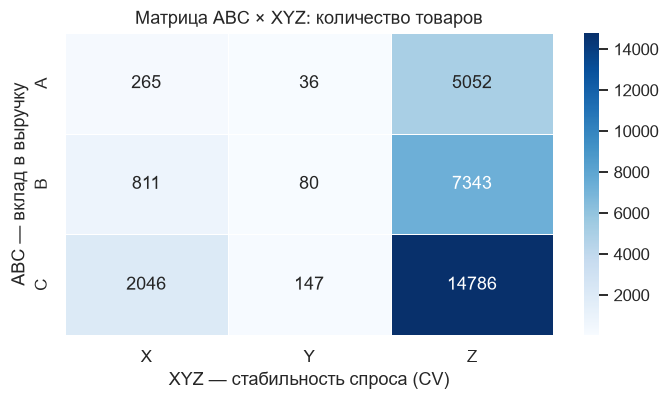

In [15]:
matrix = (
    abc.rename(columns={"group": "abc_group"})[["item", "abc_group", "total_amount"]]
    .merge(
        xyz.rename(columns={"group": "xyz_group"})[["item", "xyz_group"]],
        on="item",
        how="left",
    )
)

pivot_counts = pd.pivot_table(
    matrix, index="abc_group", columns="xyz_group",
    values="item", aggfunc="count", fill_value=0,
).reindex(index=["A", "B", "C"], columns=["X", "Y", "Z"])

pivot_revenue = pd.pivot_table(
    matrix, index="abc_group", columns="xyz_group",
    values="total_amount", aggfunc="sum", fill_value=0,
).reindex(index=["A", "B", "C"], columns=["X", "Y", "Z"])

print("Количество товаров (ABC × XYZ):")
print(pivot_counts.to_string())
print("\nВыручка, руб.:")
print(pivot_revenue.to_string(float_format=fmt_num))
print("\nДоля выручки, %:")
print((pivot_revenue / pivot_revenue.values.sum() * 100).to_string(float_format=fmt_num))

# плоская таблица для сохранения в CSV
abc_xyz_matrix = (
    matrix.groupby(["abc_group", "xyz_group"], as_index=False)
    .agg(товаров=("item", "count"), выручка=("total_amount", "sum"))
)
abc_xyz_matrix["доля_выручки_%"] = (
    abc_xyz_matrix["выручка"] / abc_xyz_matrix["выручка"].sum() * 100
).round(4)
print("\nПлоский вид для CSV:")
print(abc_xyz_matrix.to_string(index=False))

fig, ax = plt.subplots(figsize=(6.4, 3.8))
sns.heatmap(pivot_counts, annot=True, fmt="d", cmap="Blues", linewidths=0.6, ax=ax)
ax.set_title("Матрица ABC × XYZ: количество товаров")
ax.set_xlabel("XYZ — стабильность спроса (CV)")
ax.set_ylabel("ABC — вклад в выручку")
fig.tight_layout()
plt.show()


## Шаг 15. Функция abc_xyz_analysis и сравнение периодов

**Промпт к AI-ассистенту:**

> 1. Создай функцию abc_xyz_analysis(df, abc_threshold_a=80,
> abc_threshold_b=95): - Которая выполняет весь ABC-XYZ анализ из предыдущих
> инструкций - Параметры позволяют менять границы групп A и B 2. Отфильтруй
> исходный DataFrame за последние 6 месяцев (с 01.05.2019 по 31.10.2019)
> 3. Запусти функцию на отфильтрованных данных: abc_xyz_analysis(df_last_6m)
> 4. Сравни результаты за весь период и за последние 6 месяцев: - Сколько
> товаров перешло из группы в группу? - Какие товары стали важнее? Какие -
> менее важны? Используй только товары, которые есть в обоих периодах

In [16]:
def abc_xyz_analysis(df, abc_threshold_a=80, abc_threshold_b=95, with_zeros=False):
    # весь ABC-XYZ-анализ: ABC по сумме продаж, XYZ по CV количества
    if not 0 < abc_threshold_a <= abc_threshold_b <= 100:
        raise ValueError("Нужно 0 < abc_threshold_a <= abc_threshold_b <= 100")

    result = (
        df.groupby("item", as_index=False)
        .agg(total_quantity=("quantity", "sum"), total_amount=("amount", "sum"))
        .sort_values("total_amount", ascending=False)
        .reset_index(drop=True)
    )

    # ABC
    total_sum = result["total_amount"].sum()
    result["cumulative_pct"] = result["total_amount"].cumsum() / total_sum * 100
    result["abc_group"] = np.select(
        [
            result["cumulative_pct"] <= abc_threshold_a,
            result["cumulative_pct"] <= abc_threshold_b,
        ],
        ["A", "B"],
        default="C",
    )

    # XYZ
    monthly = (
        df.assign(month=df["tr_date"].dt.to_period("M"))
        .groupby(["item", "month"], as_index=False)["quantity"]
        .sum()
    )
    pivot = monthly.pivot(index="item", columns="month", values="quantity").fillna(0)
    series = pivot if with_zeros else pivot.replace(0, np.nan)
    cv = series.std(axis=1, ddof=1) / series.mean(axis=1) * 100

    result["months"] = result["item"].map((pivot > 0).sum(axis=1))
    result["cv"] = result["item"].map(cv)
    result["xyz_group"] = np.select(
        [result["cv"] < 15, result["cv"] <= 25], ["X", "Y"], default="Z"
    )
    result["abc_xyz"] = result["abc_group"] + result["xyz_group"]
    return result


full = abc_xyz_analysis(df)

# период из задания — ровно 01.05.2019–31.10.2019.
# В шаге 6 start_date считался как end_date - 6 месяцев и дал 30.04.2019
# (pandas прижимает 31-е к последнему дню апреля), здесь границы заданы явно.
df_6m = df[
    (df["tr_date"] >= pd.Timestamp("2019-05-01"))
    & (df["tr_date"] <= pd.Timestamp("2019-10-31"))
]
recent = abc_xyz_analysis(df_6m)
print(f"Строк за 01.05–31.10.2019: {fmt_int(len(df_6m))}")

print(f"Товаров: весь период — {fmt_int(len(full))}, 6 месяцев — {fmt_int(len(recent))}")
print("\nПроверка параметров границ:")
for a, b in [(80, 95), (70, 90)]:
    part = abc_xyz_analysis(df, abc_threshold_a=a, abc_threshold_b=b)
    counts = part["abc_group"].value_counts().reindex(["A", "B", "C"])
    print(f"  A<={a} %, B<={b} %: A={counts['A']}, B={counts['B']}, C={counts['C']}")

common = full.merge(recent, on="item", suffixes=("_full", "_6m"))
print(f"\nТоваров в обоих периодах: {fmt_int(len(common))}")

abc_transitions = pd.crosstab(common["abc_group_full"], common["abc_group_6m"]).reindex(
    index=["A", "B", "C"], columns=["A", "B", "C"]
).fillna(0).astype(int)
xyz_transitions = pd.crosstab(common["xyz_group_full"], common["xyz_group_6m"]).reindex(
    index=["X", "Y", "Z"], columns=["X", "Y", "Z"]
).fillna(0).astype(int)

print("\nПереходы ABC (строки — весь период, столбцы — 6 месяцев):")
print(abc_transitions.to_string())
print("\nПереходы XYZ:")
print(xyz_transitions.to_string())

moved_abc = int((common["abc_group_full"] != common["abc_group_6m"]).sum())
moved_xyz = int((common["xyz_group_full"] != common["xyz_group_6m"]).sum())
print(
    f"\nСменили ABC-группу: {fmt_int(moved_abc)} ({fmt_num(moved_abc / len(common) * 100)} %), "
    f"XYZ-группу: {fmt_int(moved_xyz)} ({fmt_num(moved_xyz / len(common) * 100)} %)"
)

common["share_full"] = common["total_amount_full"] / common["total_amount_full"].sum() * 100
common["share_6m"] = common["total_amount_6m"] / common["total_amount_6m"].sum() * 100
common["share_delta_pp"] = common["share_6m"] - common["share_full"]

cols = ["item", "abc_group_full", "abc_group_6m", "share_full", "share_6m", "share_delta_pp"]
fmt = {
    "share_full": lambda x: fmt_num(x, 3),
    "share_6m": lambda x: fmt_num(x, 3),
    "share_delta_pp": lambda x: f"{x:+.3f}".replace(".", ","),
}
print("\nСтали важнее (рост доли выручки, п.п.):")
print(common.nlargest(5, "share_delta_pp")[cols].to_string(index=False, formatters=fmt))
print("\nСтали менее важны (падение доли выручки, п.п.):")
print(common.nsmallest(5, "share_delta_pp")[cols].to_string(index=False, formatters=fmt))


Строк за 01.05–31.10.2019: 347 736
Товаров: весь период — 30 566, 6 месяцев — 21 767

Проверка параметров границ:
  A<=80 %, B<=95 %: A=5353, B=8234, C=16979
  A<=70 %, B<=90 %: A=3239, B=6181, C=21146

Товаров в обоих периодах: 21 767

Переходы ABC (строки — весь период, столбцы — 6 месяцев):
abc_group_6m       A     B      C
abc_group_full                   
A               3341  1007    173
B                515  3944   1776
C                  0   831  10180

Переходы XYZ:
xyz_group_6m       X    Y      Z
xyz_group_full                  
X               1007    1    913
Y                  7   83     71
Z               1206  529  17950

Сменили ABC-группу: 4 302 (19,76 %), XYZ-группу: 2 727 (12,53 %)

Стали важнее (рост доли выручки, п.п.):
    item abc_group_full abc_group_6m share_full share_6m share_delta_pp
sku22208              A            A      0,211    0,386         +0,175
 sku3243              A            A      0,153    0,287         +0,133
sku23883              A         

## Шаг 16. Сохранение результатов в CSV

**Промпт к AI-ассистенту:**

> Сохрани результаты анализа в CSV файлы: Результаты ТОП-5 товаров →
> 'top_5_products.csv' 2. Статистику по клиентам → 'client_statistics.csv'
> ABC-анализ товаров → 'abc_analysis.csv' XYZ-анализ товаров →
> 'xyz_analysis.csv' Матрицу ABC-XYZ → 'abc_xyz_matrix.csv' Данные за
> последние 6 месяцев → 'last_6_months_data.csv'. Используй method='w',
> index=False для сохранения без индекса Проверь, что файлы успешно созданы,
> выведи первые 5 строк каждого файла

`last_6_months_data.csv` берётся из шага 6, то есть период 30.04–31.10.2019
(350 864 строки) — так, как его посчитал `start_date = end_date - 6 месяцев`.

In [17]:
files = {
    "top_5_products.csv": top_5_products,
    "client_statistics.csv": client_stats,
    "abc_analysis.csv": abc,
    "xyz_analysis.csv": xyz,
    "abc_xyz_matrix.csv": abc_xyz_matrix,
    "last_6_months_data.csv": df_last_6m,
}

for name, table in files.items():
    table.to_csv(name, mode="w", index=False)
    print(f"сохранено: {name:<26} {len(table):>7,} строк × {table.shape[1]:>2} колонки".replace(",", " "))

print("\nПроверка файлов на диске:")
for name in files:
    path = Path(name)
    status = "OK " if path.exists() else "НЕТ"
    size = path.stat().st_size if path.exists() else 0
    print(f"  {status} {name:<26} {size:>10,} байт".replace(",", " "))

print("\nПервые 5 строк каждого файла:")
for name in files:
    print(f"\n--- {name} ---")
    print(pd.read_csv(name, nrows=5).to_string(index=False))


сохранено: top_5_products.csv               5 строк ×  3 колонки
сохранено: client_statistics.csv       42 746 строк ×  4 колонки
сохранено: abc_analysis.csv            30 566 строк ×  6 колонки
сохранено: xyz_analysis.csv            30 566 строк ×  8 колонки
сохранено: abc_xyz_matrix.csv               9 строк ×  5 колонки
сохранено: last_6_months_data.csv     350 864 строк ×  7 колонки

Проверка файлов на диске:
  OK  top_5_products.csv                138 байт
  OK  client_statistics.csv         984 578 байт
  OK  abc_analysis.csv            1 448 036 байт
  OK  xyz_analysis.csv            1 816 715 байт
  OK  abc_xyz_matrix.csv                301 байт
  OK  last_6_months_data.csv     29 760 949 байт

Первые 5 строк каждого файла:

--- top_5_products.csv ---
    item  quantity  amount
sku26161     18902 5373638
sku18199      7250 3951361
sku21947     15304 3918570
sku28128      7705 3027786
 sku8342      3512 2113158

--- client_statistics.csv ---
     client  total_quantity  total_am

## Итоги

Что получилось на 1 008 688 транзакциях:

* **Данные чистые**: пропусков нет, дата разобрана в `datetime`, нашлась одна
  ошибка ввода (`quantity = 0`) и 17 строк с нулевой суммой.
* **Распределения с тяжёлым правым хвостом**: средний чек 623 руб. при медиане
  150; средняя цена единицы 390 руб. при медиане 103.
* **Клиенты**: 42 746 человек, 30,1 % приходили в одну дату и дают 7,2 %
  выручки; 9 клиентов-экстремумов дают 1,46 % выручки.
* **Товары**: 30 566 SKU, ТОП-5 дают 2,92 % выручки; ABC — 17,5 % ассортимента
  приносят 80 % денег; XYZ — 88,9 % товаров в группе Z.
* **Главный вывод**: 77,8 % выручки сосредоточено в ячейке AZ (много продаж,
  нестабильный спрос) — именно там нужны прогноз и страховой запас, а не в
  стабильном, но экономически мелком сегменте X.
